# 02 · Step 2: Customer profiles (gate K3)
**Goal:** turn 45.8M purchase lines into **one row per customer** (about 70 measures) that describe how each person shops, using only data up to **18 Mar 2019**.

**Why so many measures:** the uplift model must find *who changes behaviour because of a message*. We give it every standard lens used in retail CRM, then let the model (Step 3) and later checks decide which ones matter.

| Group | Industry name | What it captures |
|---|---|---|
| A | Recency / lifecycle (RFM-R, BG/NBD inputs) | How long since the last visit; is the customer *overdue* versus their own rhythm |
| B | Frequency + inter-purchase time | How often, how regularly |
| C | Monetary | How much, typical and extreme bills |
| D | Velocity / trend | Speeding up or slowing down (last 30 days vs the 30 before) |
| E | Basket | Size, variety, habit (repeat products) |
| F | Loyalty economy | Points earned, spent, share of value paid with points |
| G | Promo sensitivity | Express (bonus) points: the strongest signal in the X5 competition's top solutions |
| H | Store loyalty | Number of stores, share at the main store |
| I | Time habits | Weekend, morning, evening, holiday shopping |
| J | Card / profile | Card age, redeem history (capped at cut-off), age, gender |

**Cleaning rules applied:** ages 14–100 · gender U kept · spend once per bill · bill = transaction + customer · line amounts not quantity · nothing after 18 Mar 2019.

## Cell 0 · Setup
Reuses the Parquet file built in Step 1. DuckDB may spill to a temp folder on disk for the big group-bys; that is normal.

In [1]:
import pandas as pd, numpy as np, duckdb, time
import matplotlib.pyplot as plt
from pathlib import Path
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 80); pd.set_option('display.max_rows', 120)

RAW  = Path('..') / 'data_x5' / 'raw'
PQ   = Path('..') / 'data_x5' / 'parquet'
FEAT = Path('..') / 'data_x5' / 'features'; FEAT.mkdir(exist_ok=True)
TMP  = Path('..') / 'data_x5' / 'tmp';      TMP.mkdir(exist_ok=True)
CUTOFF = '2019-03-18'          # last day of purchase history

exp = pd.read_csv(RAW / 'uplift_train.csv.gz')
cli = pd.read_csv(RAW / 'clients.csv.gz', parse_dates=['first_issue_date', 'first_redeem_date'])

con = duckdb.connect()
con.execute(f"SET temp_directory='{TMP.as_posix()}'")
con.execute("SET preserve_insertion_order=false")
con.sql(f"CREATE OR REPLACE VIEW pur AS SELECT * FROM '{(PQ / 'purchases.parquet').as_posix()}'")
con.register('exp', exp); con.register('cli', cli)
print('ready')

ready


## Cell 1 · Bill table (rule 3 and 4)
One row per bill (transaction + customer). Bill-level fields (total, points, store, time) are taken once; line-level amounts are summed.
`days_ago` = days before the cut-off (0 = 18 Mar 2019).

In [2]:
t0 = time.time()
con.sql(f'''
CREATE OR REPLACE TABLE bills AS
SELECT client_id, transaction_id,
       MIN(transaction_datetime)                          AS dt,
       date_diff('day', CAST(MIN(transaction_datetime) AS DATE), DATE '{CUTOFF}') AS days_ago,
       MAX(purchase_sum)                                  AS bill_sum,
       MAX(regular_points_received)                       AS reg_earn,
       MAX(ABS(regular_points_spent))                     AS reg_spent,
       MAX(express_points_received)                       AS exp_earn,
       MAX(ABS(express_points_spent))                     AS exp_spent,
       ANY_VALUE(store_id)                                AS store_id,
       COUNT(*)                                           AS n_lines,
       SUM(product_quantity)                              AS qty,
       SUM(trn_sum_from_iss)                              AS line_value,
       SUM(COALESCE(trn_sum_from_red, 0))                 AS paid_with_points
FROM pur
WHERE transaction_datetime < DATE '{CUTOFF}' + INTERVAL 1 DAY
GROUP BY client_id, transaction_id
''')
print(con.sql('SELECT COUNT(*) bills, COUNT(DISTINCT client_id) customers, MIN(days_ago) min_days_ago, MAX(days_ago) max_days_ago FROM bills').df())
print(f'{time.time()-t0:.0f}s')

     bills  customers  min_days_ago  max_days_ago
0  8045229     400162             0           117
4s


## Cell 2 · Customer measures (groups A–I)
One query builds every purchase-based measure per customer. Helper tables:
- **gaps**: days between consecutive shopping days → regularity and "overdue" signal
- **prod**: how often each product repeats → habit and concentration
- **store**: bills per store → store loyalty

In [3]:
t0 = time.time()
con.sql('''
CREATE OR REPLACE TABLE gaps AS
SELECT client_id, AVG(gap) gap_mean, STDDEV_SAMP(gap) gap_std, MAX(gap) gap_max
FROM (SELECT client_id, d - LAG(d) OVER (PARTITION BY client_id ORDER BY d) AS gap
      FROM (SELECT DISTINCT client_id, CAST(dt AS DATE) d FROM bills))
WHERE gap IS NOT NULL GROUP BY client_id''')

con.sql(f'''
CREATE OR REPLACE TABLE prod AS
SELECT client_id, COUNT(*) n_distinct_products, MAX(n) top_product_lines, SUM(n) total_lines
FROM (SELECT client_id, product_id, COUNT(*) n FROM pur
      WHERE transaction_datetime < DATE '{CUTOFF}' + INTERVAL 1 DAY GROUP BY 1, 2)
GROUP BY client_id''')

con.sql('''
CREATE OR REPLACE TABLE store AS
SELECT client_id, COUNT(*) n_stores, MAX(n) top_store_bills
FROM (SELECT client_id, store_id, COUNT(*) n FROM bills GROUP BY 1, 2) GROUP BY client_id''')

def win(col, d):  # sum of a column over the last d days
    return f"SUM(CASE WHEN days_ago < {d} THEN {col} ELSE 0 END)"

con.sql(f'''
CREATE OR REPLACE TABLE agg AS
SELECT client_id,
  -- A recency / lifecycle
  MIN(days_ago)                                   AS recency_days,
  MAX(days_ago)                                   AS days_since_first_bill,
  MAX(days_ago) - MIN(days_ago) + 1               AS active_span_days,
  -- B frequency
  COUNT(*)                                        AS n_bills,
  {win(1, 7)}  AS n_bills_7d,  {win(1, 14)} AS n_bills_14d,
  {win(1, 30)} AS n_bills_30d, {win(1, 60)} AS n_bills_60d,
  SUM(CASE WHEN days_ago BETWEEN 30 AND 59 THEN 1 ELSE 0 END) AS n_bills_prev30d,
  COUNT(DISTINCT CAST(dt AS DATE))                AS n_active_days,
  -- C monetary
  SUM(bill_sum)                                   AS spend_total,
  {win('bill_sum', 7)}  AS spend_7d,  {win('bill_sum', 14)} AS spend_14d,
  {win('bill_sum', 30)} AS spend_30d, {win('bill_sum', 60)} AS spend_60d,
  SUM(CASE WHEN days_ago BETWEEN 30 AND 59 THEN bill_sum ELSE 0 END) AS spend_prev30d,
  AVG(bill_sum) AS bill_mean, MEDIAN(bill_sum) AS bill_median, STDDEV_SAMP(bill_sum) AS bill_std,
  MAX(bill_sum) AS bill_max, MIN(bill_sum) AS bill_min,
  -- E basket
  AVG(n_lines) AS lines_per_bill, AVG(qty) AS qty_per_bill,
  SUM(line_value) / NULLIF(SUM(n_lines), 0) AS avg_line_value,
  -- F loyalty economy (regular points)
  SUM(reg_earn) AS reg_points_earned, SUM(reg_spent) AS reg_points_spent,
  {win('reg_earn', 30)} AS reg_points_earned_30d,
  AVG(reg_earn) AS reg_points_per_bill,
  AVG((reg_spent > 0)::INT) AS share_bills_reg_spent,
  SUM(paid_with_points) / NULLIF(SUM(line_value), 0) AS share_value_paid_with_points,
  -- G promo sensitivity (express points)
  SUM(exp_earn) AS exp_points_earned, SUM(exp_spent) AS exp_points_spent,
  {win('exp_earn', 30)} AS exp_points_earned_30d, {win('exp_spent', 30)} AS exp_points_spent_30d,
  AVG((exp_earn > 0)::INT)  AS share_bills_exp_earned,
  AVG((exp_spent > 0)::INT) AS share_bills_exp_spent,
  AVG(exp_spent) AS exp_points_spent_per_bill,
  -- I time habits
  AVG((dayofweek(dt) IN (0, 6))::INT)  AS share_weekend,
  AVG((hour(dt) < 12)::INT)            AS share_morning,
  AVG((hour(dt) >= 18)::INT)           AS share_evening,
  AVG(hour(dt))                        AS mean_hour,
  SUM(CASE WHEN (month(dt) = 12 AND day(dt) >= 24) OR (month(dt) = 3 AND day(dt) BETWEEN 4 AND 8)
           THEN bill_sum ELSE 0 END) / NULLIF(SUM(bill_sum), 0) AS share_spend_holidays
FROM bills GROUP BY client_id''')
print(f'{time.time()-t0:.0f}s')

55s


## Cell 3 · Derived ratios + card / profile measures (groups D and J), then save
Ratios combine the raw measures into the signals analysts actually use:
- **days_overdue_ratio** = recency ÷ usual gap. Above 1 = later than usual → at risk.
- **spend_trend_30d** = (last 30 days − previous 30) ÷ previous 30. Negative = slowing down.
- **ever_redeemed_by_cutoff** uses only redeems on or before 18 Mar 2019 (rule 6).

In [4]:
prof = con.sql(f'''
SELECT a.*,
  g.gap_mean, g.gap_std, g.gap_max,
  g.gap_std / NULLIF(g.gap_mean, 0)                     AS gap_cv,
  a.recency_days / NULLIF(g.gap_mean, 0)                AS days_overdue_ratio,
  a.n_bills * 7.0 / a.active_span_days                  AS bills_per_week,
  a.spend_total / a.active_span_days                    AS spend_per_day,
  (a.spend_30d - a.spend_prev30d) / NULLIF(a.spend_prev30d, 0)     AS spend_trend_30d,
  (a.n_bills_30d - a.n_bills_prev30d) / NULLIF(a.n_bills_prev30d, 0) AS bills_trend_30d,
  a.spend_30d / NULLIF(a.spend_total, 0)                AS share_spend_last30d,
  p.n_distinct_products,
  p.n_distinct_products * 1.0 / a.n_bills               AS distinct_products_per_bill,
  1 - p.n_distinct_products * 1.0 / p.total_lines       AS repeat_product_share,
  p.top_product_lines * 1.0 / p.total_lines             AS top_product_share,
  s.n_stores, s.top_store_bills * 1.0 / a.n_bills       AS top_store_share,
  (a.reg_points_earned + a.exp_points_earned) - (a.reg_points_spent + a.exp_points_spent) AS net_points_flow
FROM agg a LEFT JOIN gaps g USING (client_id) LEFT JOIN prod p USING (client_id) LEFT JOIN store s USING (client_id)
''').df()

c = cli.copy()
cut = pd.Timestamp(CUTOFF) + pd.Timedelta(days=1)
c['age_clean']   = c.age.where(c.age.between(14, 100))
c['age_missing'] = c.age_clean.isna().astype(int)
c['card_tenure_days'] = (cut - c.first_issue_date).dt.days
c['card_issued_in_history'] = (c.first_issue_date >= '2018-11-21').astype(int)
red_ok = c.first_redeem_date.where(c.first_redeem_date < cut)          # rule 6: future redeems become blank
c['ever_redeemed_by_cutoff'] = red_ok.notna().astype(int)
c['days_issue_to_first_redeem'] = (red_ok - c.first_issue_date).dt.days.clip(lower=0)
c['days_since_first_redeem'] = (cut - red_ok).dt.days
c = c[['client_id', 'gender', 'age_clean', 'age_missing', 'card_tenure_days', 'card_issued_in_history',
       'ever_redeemed_by_cutoff', 'days_issue_to_first_redeem', 'days_since_first_redeem']]

profiles = c.merge(prof, on='client_id', how='left').merge(exp, on='client_id', how='left')
profiles['in_experiment'] = profiles.treatment_flg.notna().astype(int)
con.register('profiles_df', profiles)
con.sql(f"COPY profiles_df TO '{(FEAT / 'customer_profiles.parquet').as_posix()}' (FORMAT PARQUET)")

FEATURES = [x for x in profiles.columns if x not in ('client_id', 'gender', 'treatment_flg', 'target', 'in_experiment')]
print(f'saved customer_profiles.parquet: {len(profiles):,} customers x {len(FEATURES)} numeric measures + gender')

saved customer_profiles.parquet: 400,162 customers x 66 numeric measures + gender


## K3 check 1 · Completeness
**Pass if:** all 200,039 experiment customers have a profile, and blanks appear only where they mean something (e.g. no redeem yet → blank redeem measures; one shopping day → no gap).

In [5]:
ex = profiles[profiles.in_experiment == 1]
print('experiment customers with a profile:', f'{len(ex):,}', '| missing bills:', ex.n_bills.isna().sum())
bl = (ex[FEATURES].isna().mean() * 100).round(2)
print('\nmeasures with blanks (% of experiment customers):'); print(bl[bl > 0].sort_values(ascending=False).to_string())

experiment customers with a profile: 200,039 | missing bills: 0

measures with blanks (% of experiment customers):
days_issue_to_first_redeem      20.07
days_since_first_redeem         20.07
bills_trend_30d                 13.45
spend_trend_30d                 13.45
gap_std                          5.05
gap_cv                           5.05
gap_mean                         2.04
gap_max                          2.04
days_overdue_ratio               2.04
bill_std                         1.91
age_clean                        0.44
share_value_paid_with_points     0.03


## K3 check 2 · No future data
**Pass if:** the latest bill used is on or before 18 Mar 2019 and no redeem date after it is used.

In [6]:
print(con.sql('SELECT MAX(dt) latest_bill_used FROM bills').df())
print('min days_since_first_redeem (must be >= 1):', profiles.days_since_first_redeem.min())

     latest_bill_used
0 2019-03-18 23:40:03
min days_since_first_redeem (must be >= 1): 0.0


## K3 check 3 · Balance on every measure
**Idea:** if the message was given at random, the two groups must look the same on all ~70 measures, not just age and gender.
**Pass if:** every standardised difference is under **0.05**.

measures over 0.05: 0 of 66 | largest: 0.0125


,treated_mean,control_mean,std_diff,abs
card_issued_in_history,0.1168,0.1209,-0.0125,0.0125
repeat_product_share,0.2558,0.2541,0.0108,0.0108
share_spend_last30d,0.3548,0.3570,-0.0094,0.0094
days_since_first_bill,97.3852,97.1526,0.0086,0.0086
card_tenure_days,434.1011,432.3600,0.0085,0.0085
active_span_days,92.5569,92.3232,0.0082,0.0082
n_bills,20.1856,20.0561,0.0073,0.0073
ever_redeemed_by_cutoff,0.8007,0.7979,0.0069,0.0069
share_bills_exp_earned,0.0009,0.0008,0.0068,0.0068
bills_trend_30d,0.4822,0.4722,0.0067,0.0067


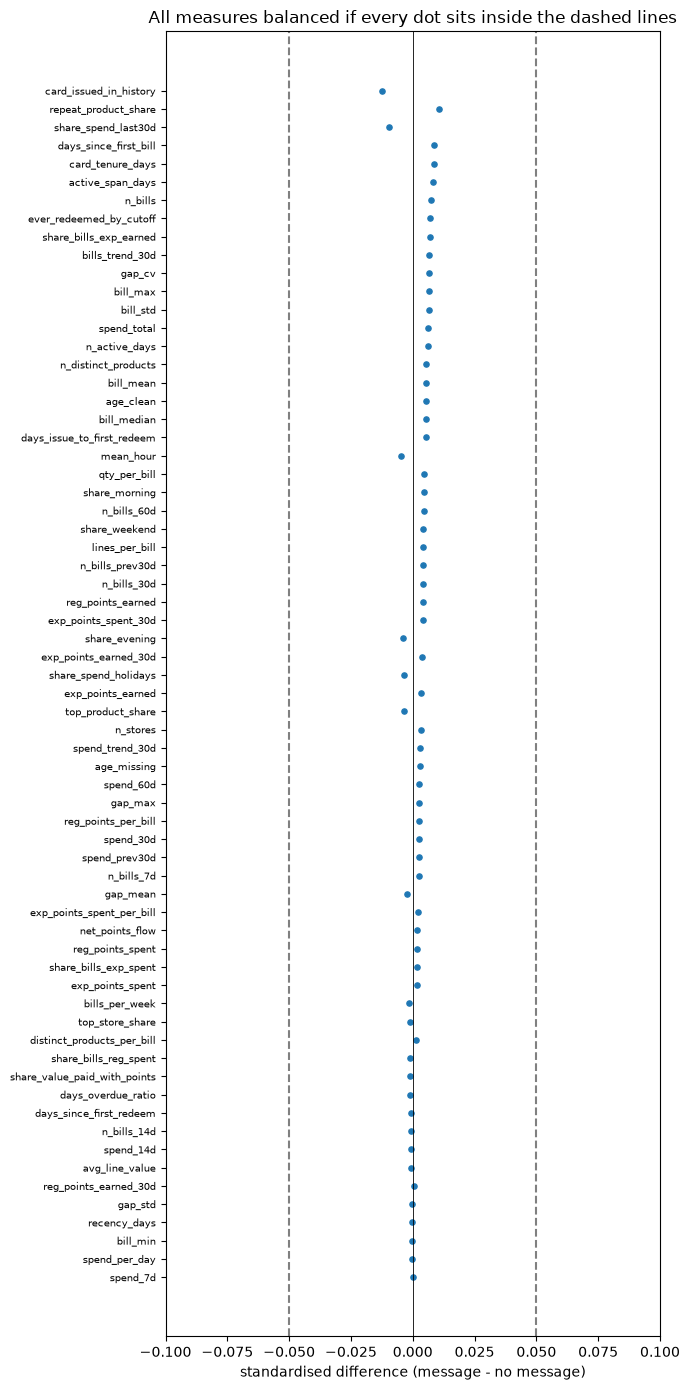

In [7]:
t, c0 = ex[ex.treatment_flg == 1], ex[ex.treatment_flg == 0]
bal = pd.DataFrame({f: {'treated_mean': t[f].mean(), 'control_mean': c0[f].mean(),
                        'std_diff': (t[f].mean() - c0[f].mean()) / np.sqrt((t[f].var() + c0[f].var()) / 2)}
                    for f in FEATURES}).T
bal['abs'] = bal.std_diff.abs(); bal = bal.sort_values('abs', ascending=False)
print('measures over 0.05:', (bal['abs'] > 0.05).sum(), 'of', len(bal), '| largest:', round(bal['abs'].max(), 4))
display(bal.head(10).round(4))

fig, ax = plt.subplots(figsize=(7, 14))
b = bal.sort_values('abs')
ax.scatter(b.std_diff, range(len(b)), s=14)
ax.axvline(0.05, ls='--', c='grey'); ax.axvline(-0.05, ls='--', c='grey'); ax.axvline(0, c='black', lw=0.6)
ax.set_yticks(range(len(b))); ax.set_yticklabels(b.index, fontsize=7)
ax.set_xlim(-0.1, 0.1); ax.set_xlabel('standardised difference (message - no message)')
ax.set_title('All measures balanced if every dot sits inside the dashed lines')
plt.tight_layout(); plt.show()

## Profile summary · what a typical customer looks like
Median and spread of key measures for the 200,039 experiment customers, plus two real rows.

In [ ]:
key = ['recency_days', 'n_bills', 'bills_per_week', 'spend_total', 'bill_mean', 'spend_trend_30d', 'days_overdue_ratio',
       'lines_per_bill', 'repeat_product_share', 'n_stores', 'share_bills_reg_spent', 'share_bills_exp_spent',
       'share_weekend', 'card_tenure_days', 'ever_redeemed_by_cutoff', 'age_clean']
display(ex[key].describe(percentiles=[.1, .25, .5, .75, .9]).T.round(2))
display(ex[['client_id'] + key].head(2).T)

## Your notes (2–3 lines in your own words)
- Did K3 pass?
- Which measure surprised you?
- Which measures do you expect to predict who responds to a message?